**Part of student 2.** This notebook holds only the cells of student 2; the other cells are in `sts-student1.ipynb`. The final notebook `sts-project.ipynb` is built from the two parts with `python sts_parts.py merge --run`.

- Edit only this notebook, not the final one. New cells are placed after the cell above them.
- The cells of the two parts are interleaved, so this notebook does not run from top to bottom by itself. To work on one cell, run the cell below with the position of that cell (`python sts_parts.py list` shows the positions): it runs everything that comes before it, from both parts.


In [ ]:
# Helper, not part of the final notebook: run the code cells of both parts that come before a position.
from sts_parts import run_before
# run_before(30)   # e.g. before working on the cell at position 30


In [8]:
# Dependency parse of every sentence with spaCy (as in Lab 8). The small English model has no word vectors.
nlp = spacy.load("en_core_web_sm")
print(f"spaCy pipeline: {nlp.pipe_names}; word vectors in the model: {nlp.vocab.vectors.shape[0]}")

start = time.time()
parsed = {key: list(zip(nlp.pipe([s1 for s1, s2 in pairs]), nlp.pipe([s2 for s1, s2 in pairs])))
          for key, (pairs, gold) in data.items()}
print(f"Parsed {2 * sum(len(v) for v in parsed.values())} sentences in {time.time() - start:.1f} s\n")

doc = parsed[("train", "MSRvid")][0][0]
pd.DataFrame([{"word": t.text, "lemma": t.lemma_, "pos": t.pos_, "dep": t.dep_, "head": t.head.text} for t in doc])

spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']; word vectors in the model: 0


Parsed 10684 sentences in 15.9 s



,word,lemma,pos,dep,head
0,A,a,DET,det,man
1,man,man,NOUN,nsubj,riding
2,is,be,AUX,aux,riding
3,riding,rid,VERB,ROOT,riding
4,a,a,DET,det,bicycle
5,bicycle,bicycle,NOUN,dobj,riding
6,.,.,PUNCT,punct,riding


### 4.2 Syntactic features (syntactic dimension alone)

These features only look at the syntactic analysis of the sentences, **not at the words**: they would give the same values for two sentences with the same structure and completely different words.

- **POS tags** (NLTK): Jaccard and cosine of the POS unigrams, bigrams and trigrams; normalized edit distance between the two POS sequences; difference of the proportion of nouns, verbs, adjectives and adverbs.
- **Chunks** (NLTK): a regular-expression chunker (`RegexpParser`, as in Lab 7) finds the NP, VP and PP chunks. Features: normalized edit distance between the sequences of chunk labels, cosine of the chunk labels, and relative difference of the number of chunks of each type.
- **Dependencies** (spaCy): Jaccard and cosine of the dependency labels and of the unlexicalized triples (category of the head, relation, category of the dependent); relative difference of the depth of the two trees.

NLTK has no pre-trained full parser (a PCFG learned from the treebank sample, as in Lab 8, is too slow and has a low coverage for these sentences), so the full syntactic analysis is the dependency parse of spaCy, and chunking is used as a shallow analysis.

In [13]:
CHUNKER = nltk.RegexpParser(r"""
    NP: {<DT|PRP\$|POS>?<JJ.*|CD|VBN|VBG>*<NN.*>+}
        {<PRP>}
        {<DT>?<CD>+}
    PP: {<IN|TO><NP>}
    VP: {<MD>?<RB.*>*<VB.*>+<RP>?}
""")

def chunk(tokens):
    """List of (label, lemmas) for each chunk of the sentence (the words outside chunks are skipped)."""
    tree = CHUNKER.parse([(t["word"], t["tag"]) for t in tokens])
    chunks, i = [], 0
    for node in tree:
        size = len(node.leaves()) if isinstance(node, nltk.Tree) else 1
        if isinstance(node, nltk.Tree):
            chunks.append((node.label(), [t["lemma"] for t in tokens[i:i + size]]))
        i += size
    return chunks

def normalized_edit_distance(a, b):
    return nltk.edit_distance(a, b) / max(len(a), len(b), 1)

def syntactic_features(t1, t2, chunks1, chunks2):
    f = {}
    tags1, tags2 = [t["tag"] for t in t1], [t["tag"] for t in t2]
    for n in (1, 2, 3):
        f[f"jaccard_pos_{n}grams"] = jaccard(ngrams(tags1, n), ngrams(tags2, n))
        f[f"cosine_pos_{n}grams"] = cosine(ngrams(tags1, n), ngrams(tags2, n))
    f["pos_edit_distance"] = normalized_edit_distance(tags1, tags2)
    for coarse in ("N", "V", "J", "R"):
        r1 = sum(t.startswith(coarse) for t in tags1) / len(tags1)
        r2 = sum(t.startswith(coarse) for t in tags2) / len(tags2)
        f[f"proportion_difference_{coarse}"] = abs(r1 - r2)

    labels1, labels2 = [label for label, _ in chunks1], [label for label, _ in chunks2]
    f["chunk_edit_distance"] = normalized_edit_distance(labels1, labels2)
    f["cosine_chunk_labels"] = cosine(labels1, labels2)
    for label in ("NP", "VP", "PP"):
        a, b = labels1.count(label), labels2.count(label)
        f[f"difference_{label}"] = abs(a - b) / max(a, b, 1)
    return f

chunks1, chunks2 = chunk(t1), chunk(t2)
print(" ".join(t["word"] for t in t1), "->", chunks1)
print(" ".join(t["word"] for t in t2), "->", chunks2)
pd.Series(syntactic_features(t1, t2, chunks1, chunks2)).round(3).to_frame("value").T

A man is riding a bicycle . -> [('NP', ['a', 'man']), ('VP', ['be', 'rid']), ('NP', ['a', 'bicycle'])]
A man is riding a bike . -> [('NP', ['a', 'man']), ('VP', ['be', 'rid']), ('NP', ['a', 'bike'])]


,jaccard_pos_1grams,cosine_pos_1grams,jaccard_pos_2grams,cosine_pos_2grams,jaccard_pos_3grams,cosine_pos_3grams,pos_edit_distance,proportion_difference_N,proportion_difference_V,proportion_difference_J,proportion_difference_R,chunk_edit_distance,cosine_chunk_labels,difference_NP,difference_VP,difference_PP
value,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [14]:
def dependency_tokens(doc):
    return [t for t in doc if not t.is_punct and not t.is_space]

def tree_depth(tokens):
    """Length of the longest path from a word to the root of the dependency tree."""
    def depth(t):
        n = 0
        while t.head.i != t.i:
            t, n = t.head, n + 1
        return n
    return max((depth(t) for t in tokens), default=0)

def dependency_features(doc1, doc2):
    """Syntactic features from the dependency trees: only labels and categories, no words."""
    d1, d2 = dependency_tokens(doc1), dependency_tokens(doc2)
    f = {}
    labels1, labels2 = [t.dep_ for t in d1], [t.dep_ for t in d2]
    f["jaccard_dep_labels"] = jaccard(labels1, labels2)
    f["cosine_dep_labels"] = cosine(labels1, labels2)
    # Unlexicalized triples: (category of the head, relation, category of the dependent)
    triples1 = [(t.head.pos_, t.dep_, t.pos_) for t in d1]
    triples2 = [(t.head.pos_, t.dep_, t.pos_) for t in d2]
    f["jaccard_dep_triples"] = jaccard(triples1, triples2)
    f["cosine_dep_triples"] = cosine(triples1, triples2)
    depth1, depth2 = tree_depth(d1), tree_depth(d2)
    f["depth_difference"] = abs(depth1 - depth2) / max(depth1, depth2, 1)
    return f

doc1, doc2 = parsed[("train", "MSRvid")][0]
print([(t.head.pos_, t.dep_, t.pos_) for t in dependency_tokens(doc1)])
pd.Series(dependency_features(doc1, doc2)).round(3).to_frame("value").T

[('NOUN', 'det', 'DET'), ('VERB', 'nsubj', 'NOUN'), ('VERB', 'aux', 'AUX'), ('VERB', 'ROOT', 'VERB'), ('NOUN', 'det', 'DET'), ('VERB', 'dobj', 'NOUN')]


,jaccard_dep_labels,cosine_dep_labels,jaccard_dep_triples,cosine_dep_triples,depth_difference
value,1.0,1.0,1.0,1.0,0.0


### 4.3 Lexico-syntactic features (combination)

These features combine both dimensions: the words are compared **within the same syntactic category or role**.

- Jaccard of the lemmas of each category separately (nouns, verbs, adjectives, adverbs), and of the (lemma, coarse POS tag) pairs.
- Jaccard of the chunks represented by their label and head (last lemma of the chunk), and of the heads of the NPs and of the VPs separately.
- Word order: proportion of pairs of shared lemmas that appear in the same order in both sentences.
- **Dependencies**: Jaccard of the lexicalized triples (lemma of the head, relation, lemma of the dependent) and of the (head, dependent) pairs of content words; and the WordNet similarity of the words with the same **role** in the two sentences (subjects, objects and main predicate), a simple comparison of the predicate-argument structure.

In [15]:
def lexico_syntactic_features(t1, t2, chunks1, chunks2):
    f = {}
    for coarse, name in [("N", "nouns"), ("V", "verbs"), ("J", "adjectives"), ("R", "adverbs")]:
        a = {t["lemma"] for t in t1 if t["tag"].startswith(coarse)}
        b = {t["lemma"] for t in t2 if t["tag"].startswith(coarse)}
        f[f"jaccard_{name}"] = jaccard(a, b)
    f["jaccard_lemma_tag"] = jaccard([(t["lemma"], t["tag"][:2]) for t in t1], [(t["lemma"], t["tag"][:2]) for t in t2])

    heads1 = [(label, lemmas[-1]) for label, lemmas in chunks1]
    heads2 = [(label, lemmas[-1]) for label, lemmas in chunks2]
    f["jaccard_chunk_heads"] = jaccard(heads1, heads2)
    for label in ("NP", "VP"):
        f[f"jaccard_{label}_heads"] = jaccard({h for l, h in heads1 if l == label}, {h for l, h in heads2 if l == label})

    lemmas1, lemmas2 = [t["lemma"] for t in t1], [t["lemma"] for t in t2]
    shared = [w for w in dict.fromkeys(lemmas1) if w in lemmas2]
    positions = [lemmas2.index(w) for w in shared]
    pairs = [(i, j) for i in range(len(positions)) for j in range(i + 1, len(positions))]
    f["word_order"] = sum(positions[i] < positions[j] for i, j in pairs) / len(pairs) if pairs else 1.0
    return f

pd.Series(lexico_syntactic_features(t1, t2, chunks1, chunks2)).round(3).to_frame("value").T

,jaccard_nouns,jaccard_verbs,jaccard_adjectives,jaccard_adverbs,jaccard_lemma_tag,jaccard_chunk_heads,jaccard_NP_heads,jaccard_VP_heads,word_order
value,0.333,1.0,1.0,1.0,0.714,0.5,0.333,1.0,1.0


In [16]:
# Syntactic roles compared with the WordNet similarity of their words (predicate-argument structure).
ROLES = {"subject": {"nsubj", "nsubjpass", "csubj"},
         "object": {"dobj", "pobj", "attr", "dative", "oprd"},
         "root": {"ROOT"}}
SPACY_TO_WORDNET = {"NOUN": wn.NOUN, "PROPN": wn.NOUN, "VERB": wn.VERB, "AUX": wn.VERB, "ADJ": wn.ADJ, "ADV": wn.ADV}

def role_similarity(words1, words2):
    """Each word of a role is aligned with the most similar word of the same role in the other sentence."""
    if not words1 or not words2:
        return float(not words1 and not words2)
    def direction(a, b):
        return sum(max(word_similarity(l1, p1, l2, p2, "path") for l2, p2 in b) for l1, p1 in a) / len(a)
    return (direction(words1, words2) + direction(words2, words1)) / 2

def lexical_dependency_features(doc1, doc2):
    """Lexico-syntactic features from the dependency trees: the words in their relations."""
    d1, d2 = dependency_tokens(doc1), dependency_tokens(doc2)
    f = {}
    # Lexicalized triples (lemma of the head, relation, lemma of the dependent), and the same without the relation
    # for the content words (the relation label often changes between active and passive, or with a wrong parse).
    f["jaccard_dep_lexical_triples"] = jaccard([(t.head.lemma_.lower(), t.dep_, t.lemma_.lower()) for t in d1 if t.dep_ != "ROOT"],
                                               [(t.head.lemma_.lower(), t.dep_, t.lemma_.lower()) for t in d2 if t.dep_ != "ROOT"])
    f["jaccard_dep_head_dependent"] = jaccard([(t.head.lemma_.lower(), t.lemma_.lower()) for t in d1 if t.dep_ != "ROOT" and not t.is_stop],
                                              [(t.head.lemma_.lower(), t.lemma_.lower()) for t in d2 if t.dep_ != "ROOT" and not t.is_stop])
    for role, relations in ROLES.items():
        words1 = [(t.lemma_.lower(), SPACY_TO_WORDNET.get(t.pos_)) for t in d1 if t.dep_ in relations]
        words2 = [(t.lemma_.lower(), SPACY_TO_WORDNET.get(t.pos_)) for t in d2 if t.dep_ in relations]
        f[f"role_{role}"] = role_similarity(words1, words2)
    return f

pd.Series(lexical_dependency_features(doc1, doc2)).round(3).to_frame("value").T

,jaccard_dep_lexical_triples,jaccard_dep_head_dependent,role_subject,role_object,role_root
value,0.429,0.333,1.0,1.0,1.0


In [17]:
# Compute all the features of every pair.
def features(t1, t2, doc1, doc2):
    chunks1, chunks2 = chunk(t1), chunk(t2)
    lexical = lexical_features(t1, t2)
    syntactic = syntactic_features(t1, t2, chunks1, chunks2) | dependency_features(doc1, doc2)
    lexico_syntactic = lexico_syntactic_features(t1, t2, chunks1, chunks2) | lexical_dependency_features(doc1, doc2)
    return ({f"lex:{k}": v for k, v in lexical.items()} | {f"syn:{k}": v for k, v in syntactic.items()}
            | {f"lexsyn:{k}": v for k, v in lexico_syntactic.items()})

start = time.time()
X = {key: pd.DataFrame([features(t1, t2, doc1, doc2) for (t1, t2), (doc1, doc2) in zip(pairs, parsed[key])])
     for key, pairs in processed.items()}
y = {key: gold for key, (pairs, gold) in data.items()}
print(f"Features computed in {time.time() - start:.1f} s")

ALL_FEATURES = list(X[("train", "MSRpar")].columns)
DEPENDENCY_FEATURES = [c for c in ALL_FEATURES if "_dep_" in c or ":role_" in c or c == "syn:depth_difference"]
FEATURE_GROUPS = {
    "lexical": [c for c in ALL_FEATURES if c.startswith("lex:")],
    "syntactic": [c for c in ALL_FEATURES if c.startswith("syn:")],
    "combined": ALL_FEATURES,
}
print({group: len(columns) for group, columns in FEATURE_GROUPS.items()},
      f"| lexico-syntactic: {sum(c.startswith('lexsyn:') for c in ALL_FEATURES)}",
      f"| from the dependency trees: {len(DEPENDENCY_FEATURES)}")

Features computed in 42.8 s
{'lexical': 24, 'syntactic': 21, 'combined': 59} | lexico-syntactic: 14 | from the dependency trees: 10


In [20]:
MODELS = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "SVR": lambda: make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=0.2)),
    "RF": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=0),
    "GBR": lambda: GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                             subsample=0.8, random_state=0),
}

def cross_validate(columns, make_model, strategy, folds=5, seed=0):
    """Cross-validation predictions for the three training sets.
    The same folds are used for both strategies: in each fold, the single model is trained on the
    training folds of the three sets, and the per-dataset models on the training folds of their own set."""
    split = {s: list(KFold(folds, shuffle=True, random_state=seed).split(X[("train", s)])) for s in TRAIN_SETS}
    predictions = {s: np.zeros(len(y[("train", s)])) for s in TRAIN_SETS}
    for k in range(folds):
        if strategy == "single":
            model = make_model().fit(
                pd.concat([X[("train", s)].iloc[split[s][k][0]][columns] for s in TRAIN_SETS]),
                np.concatenate([y[("train", s)][split[s][k][0]] for s in TRAIN_SETS]))
        for s in TRAIN_SETS:
            train_idx, test_idx = split[s][k]
            if strategy == "per dataset":
                model = make_model().fit(X[("train", s)].iloc[train_idx][columns], y[("train", s)][train_idx])
            predictions[s][test_idx] = model.predict(X[("train", s)].iloc[test_idx][columns])
    return {s: np.clip(p, 0, 5) for s, p in predictions.items()}

start = time.time()
cv_results = []
for group, columns in FEATURE_GROUPS.items():
    for model_name, make_model in MODELS.items():
        for strategy in ["single", "per dataset"]:
            predictions = cross_validate(columns, make_model, strategy)
            cv_results.append({"features": group, "model": model_name, "strategy": strategy,
                               **scores(train_gold, predictions, TRAIN_SETS)})
cv_results = pd.DataFrame(cv_results)
print(f"Cross-validation done in {time.time() - start:.0f} s")
cv_results.sort_values("ALL", ascending=False).round(4)

Cross-validation done in 53 s


,features,model,strategy,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl
21,combined,RF,per dataset,0.8889,0.8889,0.7716,0.7079,0.8604,0.7459
23,combined,GBR,per dataset,0.8841,0.8844,0.7660,0.7062,0.8503,0.7411
5,lexical,RF,per dataset,0.8836,0.8837,0.7633,0.7115,0.8490,0.7285
7,lexical,GBR,per dataset,0.8807,0.8814,0.7559,0.7080,0.8471,0.7117
3,lexical,SVR,per dataset,0.8806,0.8809,0.7631,0.7205,0.8394,0.7287
19,combined,SVR,per dataset,0.8795,0.8800,0.7558,0.6849,0.8458,0.7362
1,lexical,Ridge,per dataset,0.8782,0.8783,0.7631,0.7322,0.8294,0.7270
17,combined,Ridge,per dataset,0.8748,0.8751,0.7535,0.7229,0.8266,0.7101
20,combined,RF,single,0.8737,0.8839,0.7524,0.6843,0.8597,0.7123
22,combined,GBR,single,0.8728,0.8813,0.7505,0.6882,0.8525,0.7099


In [21]:
# Best configuration of each feature set (by cross-validation ALL), and the selected system.
best_cv = cv_results.loc[cv_results.groupby("features")["ALL"].idxmax()].set_index("features")
SELECTED = best_cv["ALL"].idxmax()
print(f"Selected system: {SELECTED} features, {best_cv.loc[SELECTED, 'model']}, {best_cv.loc[SELECTED, 'strategy']}\n")
best_cv.loc[["lexical", "syntactic", "combined"]].round(4)

Selected system: combined features, RF, per dataset



,model,strategy,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl
features,,,,,,,,
lexical,RF,per dataset,0.8836,0.8837,0.7633,0.7115,0.8490,0.7285
syntactic,RF,per dataset,0.6972,0.6992,0.4856,0.3864,0.3577,0.7176
combined,RF,per dataset,0.8889,0.8889,0.7716,0.7079,0.8604,0.7459


**The selected system is: combined features, random forest, one model per dataset** (CV ALL = 0.8889).

- **One model per dataset is better for every feature set and every model.** For the combined features and the random forest, ALL goes from 0.8737 (single) to 0.8889.
- **A linear model is already close.** Ridge with the lexical features and one model per dataset reaches 0.8782, against 0.8836 for the random forest. Most of the gain comes from learning the weights, and a little more from the non-linear model.
- **Syntax alone is far below** (best: 0.6972), and it only works on SMTeuroparl (0.7176), where a bad translation often has a broken structure. On MSRpar and MSRvid it stays below 0.39.
- **The combination is slightly better than the lexical features** (0.8889 against 0.8836).

### 5.3 How reliable are these differences?

The differences between the best configurations are small, so two checks are made before trusting them: the variation of the cross-validation itself, and the sensitivity to the hyperparameters.

In [22]:
# How large is the noise of the cross-validation? The same configurations with five different fold assignments.
noise = []
for group, model_name, strategy in [(SELECTED, best_cv.loc[SELECTED, "model"], best_cv.loc[SELECTED, "strategy"]),
                                    ("lexical", best_cv.loc[SELECTED, "model"], best_cv.loc[SELECTED, "strategy"]),
                                    (SELECTED, best_cv.loc[SELECTED, "model"], "single")]:
    runs = [scores(train_gold, cross_validate(FEATURE_GROUPS[group], MODELS[model_name], strategy, seed=seed), TRAIN_SETS)
            for seed in range(5)]
    noise.append({"features": group, "model": model_name, "strategy": strategy,
                  "ALL mean": np.mean([r["ALL"] for r in runs]), "ALL std": np.std([r["ALL"] for r in runs]),
                  "ALL min": np.min([r["ALL"] for r in runs]), "ALL max": np.max([r["ALL"] for r in runs]),
                  "Mean mean": np.mean([r["Mean"] for r in runs]), "Mean std": np.std([r["Mean"] for r in runs])})
cv_noise = pd.DataFrame(noise)
cv_noise.round(4)

,features,model,strategy,ALL mean,ALL std,ALL min,ALL max,Mean mean,Mean std
0,combined,RF,per dataset,0.8886,0.0010,0.8877,0.8904,0.7728,0.0017
1,lexical,RF,per dataset,0.8825,0.0015,0.8808,0.8848,0.7634,0.0027
2,combined,RF,single,0.8733,0.0014,0.8715,0.8757,0.7522,0.0027


In [23]:
# Sensitivity to the hyperparameters of the random forest (combined features, one model per dataset).
grid = []
for leaf in [1, 3, 5, 10]:
    for max_features in [1.0, 0.5, 0.33]:
        make_model = lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, max_features=max_features,
                                                   n_jobs=-1, random_state=0)
        result = scores(train_gold, cross_validate(FEATURE_GROUPS["combined"], make_model, "per dataset"), TRAIN_SETS)
        grid.append({"min_samples_leaf": leaf, "max_features": max_features, "ALL": result["ALL"], "Mean": result["Mean"]})
grid = pd.DataFrame(grid)
print(f"Range of CV ALL over the grid: {grid['ALL'].min():.4f} to {grid['ALL'].max():.4f}  (used: min_samples_leaf=3, max_features=1.0)")
grid.pivot(index="min_samples_leaf", columns="max_features", values="ALL").round(4)

Range of CV ALL over the grid: 0.8825 to 0.8906  (used: min_samples_leaf=3, max_features=1.0)


max_features,0.33,0.50,1.00
min_samples_leaf,,,
1,0.8899,0.8906,0.8893
3,0.8901,0.8892,0.8889
5,0.8890,0.8888,0.8877
10,0.8831,0.8825,0.8825


- **Noise of the cross-validation.** With five different assignments of the pairs to the folds, the ALL of the selected configuration varies between 0.8877 and 0.8904 (standard deviation 0.0010). Differences of about 0.002 or less between two configurations are therefore not meaningful. The gain of the combination over the lexical features (0.8886 against 0.8825 on average) and the gain of one model per dataset (0.8886 against 0.8733) are larger than this noise.
- **Hyperparameters.** Over the 12 settings of the random forest, the CV ALL goes from 0.8825 to 0.8906. The best setting (`min_samples_leaf=1`, `max_features=0.5`) is only 0.0017 above the one we use (0.8889), which is inside the noise of the cross-validation, so the initial setting is kept. Only very large leaves (`min_samples_leaf=10`) are clearly worse. The system is not sensitive to these hyperparameters.

### 5.4 A source without training data

Two of the test sets (OnWN and SMTnews) come from sources that are not in the training data. To estimate what to expect, each training set is predicted with models trained only on the other ones.

In [24]:
# Sources without training data: train on two training sets and predict the third one (leave one dataset out),
# compared with the cross-validation inside the same dataset.
make_model = MODELS[best_cv.loc[SELECTED, "model"]]
columns = FEATURE_GROUPS[SELECTED]
in_domain = cv_results[(cv_results["features"] == SELECTED) & (cv_results["model"] == best_cv.loc[SELECTED, "model"])
                       & (cv_results["strategy"] == "per dataset")].iloc[0]
unseen = []
for held_out in TRAIN_SETS:
    others = [s for s in TRAIN_SETS if s != held_out]
    row = {"held-out set": held_out, "own model (CV)": in_domain[held_out]}
    for name, sets in {"other two together": others, **{f"only {s}": [s] for s in others}}.items():
        model = make_model().fit(pd.concat([X[("train", s)][columns] for s in sets]),
                                 np.concatenate([y[("train", s)] for s in sets]))
        row[name] = pearsonr(y[("train", held_out)], model.predict(X[("train", held_out)][columns]))[0]
    unseen.append(row)
unseen = pd.DataFrame(unseen).set_index("held-out set")
unseen.round(4)

,own model (CV),other two together,only MSRvid,only SMTeuroparl,only MSRpar
held-out set,,,,,
MSRpar,0.7079,0.5998,0.6421,0.5391,NaN
MSRvid,0.8604,0.5787,NaN,0.6322,0.7509
SMTeuroparl,0.7459,0.5955,0.5822,NaN,0.5315


**On a source that the model has not seen, the correlation drops a lot.** A model trained on the other two training sets gives 0.5998 on MSRpar (0.7079 with its own model, in cross-validation), 0.5787 on MSRvid (0.8604) and 0.5955 on SMTeuroparl (0.7459). The choice of the training data also matters: for MSRvid, the model trained only on MSRpar (0.7509) is much better than the one trained on MSRpar and SMTeuroparl together (0.5787). So for the surprise sets we should expect lower correlations than for the known sets, and a model trained on a similar source is preferable when there is one: this is the reason for predicting SMTnews with the SMTeuroparl model.

## 6. Results on the test set

Each configuration is now trained on the whole training data and evaluated on the five test sets. The **selected system** is the one chosen by cross-validation in the previous section; the other configurations are shown to compare the feature sets, models and strategies, not to choose among them.

In [25]:
SURPRISE_MODEL = {"surprise.OnWN": None, "surprise.SMTnews": "SMTeuroparl"}  # None: single model

def train_and_predict(columns, make_model, strategy, surprise_model=SURPRISE_MODEL):
    single = make_model().fit(pd.concat([X[("train", s)][columns] for s in TRAIN_SETS]),
                              np.concatenate([y[("train", s)] for s in TRAIN_SETS]))
    per_dataset = {s: make_model().fit(X[("train", s)][columns], y[("train", s)]) for s in TRAIN_SETS} \
        if strategy == "per dataset" else {}
    predictions = {}
    for s in TEST_SETS:
        source = s if s in TRAIN_SETS else surprise_model[s]
        model = per_dataset.get(source, single)
        predictions[s] = np.clip(model.predict(X[("test", s)][columns]), 0, 5)
    return predictions

test_predictions, test_results = {}, []
for group, columns in FEATURE_GROUPS.items():
    for model_name, make_model in MODELS.items():
        for strategy in ["single", "per dataset"]:
            predictions = train_and_predict(columns, make_model, strategy)
            test_predictions[(group, model_name, strategy)] = predictions
            test_results.append({"features": group, "model": model_name, "strategy": strategy, **evaluate(predictions)})
test_results = pd.DataFrame(test_results)

def official_rank(value, measure="ALL"):
    """Rank that a run with this score would have had in the official ranking (89 runs)."""
    return int((official[measure] > value).sum()) + 1

test_results["rank (ALL)"] = test_results["ALL"].map(official_rank)
test_results.round(4)

,features,model,strategy,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews,rank (ALL)
0,lexical,Ridge,single,0.7239,0.8395,0.6462,0.6306,0.8281,0.4284,0.6929,0.4962,18
1,lexical,Ridge,per dataset,0.8045,0.8522,0.6688,0.6886,0.8485,0.4274,0.6929,0.5267,5
2,lexical,SVR,single,0.7750,0.8588,0.6824,0.6897,0.8582,0.4873,0.7260,0.4804,9
3,lexical,SVR,per dataset,0.8201,0.8607,0.6880,0.7052,0.8546,0.4315,0.7260,0.5662,2
4,lexical,RF,single,0.7722,0.8567,0.6833,0.6891,0.8597,0.5275,0.6937,0.5001,9
5,lexical,RF,per dataset,0.8199,0.8621,0.6970,0.6879,0.8684,0.5391,0.6937,0.5794,2
6,lexical,GBR,single,0.7743,0.8538,0.6724,0.6699,0.8583,0.4883,0.6890,0.5078,9
7,lexical,GBR,per dataset,0.8207,0.8572,0.6817,0.6731,0.8618,0.4778,0.6890,0.5803,2
8,syntactic,Ridge,single,0.1125,0.5925,0.0612,0.0834,0.0779,-0.1552,0.1453,0.0794,89
9,syntactic,Ridge,per dataset,0.5151,0.6308,0.2888,0.3419,0.2900,0.3884,0.1453,0.3420,61


In [26]:
# The selected system and the best of each feature set (chosen by cross-validation), on the test set.
chosen = [(group, best_cv.loc[group, "model"], best_cv.loc[group, "strategy"]) for group in ["lexical", "syntactic", "combined"]]
summary = test_results.set_index(["features", "model", "strategy"]).loc[chosen]
for measure in ["ALLnrm", "Mean"]:
    summary[f"rank ({measure})"] = summary[measure].map(lambda v: official_rank(v, measure))
SYSTEM = (SELECTED, best_cv.loc[SELECTED, "model"], best_cv.loc[SELECTED, "strategy"])
system_result = summary.loc[SYSTEM]
print(f"Selected system {SYSTEM}: ALL = {system_result['ALL']:.4f} (rank {int(system_result['rank (ALL)'])} of {len(official) + 1})")
summary.round(4)

Selected system ('combined', 'RF', 'per dataset'): ALL = 0.8263 (rank 1 of 90)


,,,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews,rank (ALL),rank (ALLnrm),rank (Mean)
features,model,strategy,,,,,,,,,,,
lexical,RF,per dataset,0.8199,0.8621,0.6970,0.6879,0.8684,0.5391,0.6937,0.5794,2,2,1
syntactic,RF,per dataset,0.5384,0.6465,0.3163,0.3758,0.3597,0.3030,0.2226,0.3145,59,88,87
combined,RF,per dataset,0.8263,0.8654,0.6946,0.6929,0.8784,0.5101,0.6967,0.5610,1,1,1


In [27]:
# Comparison with the official ranking: our selected system inserted among the top runs and the baseline.
ours = {"run": f"OURS: {' / '.join(SYSTEM)}", **{k: system_result[k] for k in ["ALL", "ALLnrm", "Mean"] + TEST_SETS}}
comparison = pd.concat([official, pd.DataFrame([ours])]).sort_values("ALL", ascending=False).reset_index(drop=True)
comparison.index += 1
for measure in ["ALL", "ALLnrm", "Mean"]:
    best = official.loc[official[measure].idxmax()]
    print(f"Best official {measure:<6} {best[measure]:.4f} ({best['run']})   ours: {system_result[measure]:.4f}")
comparison[(comparison.index <= 12) | comparison["run"].str.contains("baseline")].round(4)

Best official ALL    0.8239 (baer/UKP-run2_plus_postprocessing_smt_twsi)   ours: 0.8263
Best official ALLnrm 0.8635 (jan_snajder/takelab-simple)   ours: 0.8654
Best official Mean   0.6773 (baer/UKP-run2_plus_postprocessing_smt_twsi)   ours: 0.6946


,run,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews
1,OURS: combined / RF / per dataset,0.8263,0.8654,0.6946,0.6929,0.8784,0.5101,0.6967,0.5610
2,baer/UKP-run2_plus_postprocessing_smt_twsi,0.8239,0.8579,0.6773,0.6830,0.8739,0.5280,0.6641,0.4937
3,jan_snajder/takelab-syntax,0.8138,0.8569,0.6601,0.6985,0.8620,0.3612,0.7049,0.4683
4,jan_snajder/takelab-simple,0.8133,0.8635,0.6753,0.7343,0.8803,0.4771,0.6797,0.3989
5,baer/UKP-run1,0.8116,0.8559,0.6708,0.6821,0.8708,0.5118,0.6649,0.4672
6,rada/UNT-IndividualRegression,0.7846,0.8440,0.6162,0.5353,0.8750,0.4203,0.6715,0.4033
7,mheilman/ETS-PERPphrases,0.7834,0.8089,0.6399,0.6397,0.7200,0.4850,0.7124,0.5312
8,mheilman/ETS-PERP,0.7808,0.8064,0.6305,0.6211,0.7210,0.4722,0.7080,0.5149
9,baer/UKP-run3_plus_random,0.7790,0.8166,0.4320,0.6830,0.8739,0.5280,-0.0620,-0.0520
10,rada/UNT-IndividualDecTree,0.7677,0.8389,0.5947,0.5693,0.8688,0.4203,0.6491,0.2256


In [28]:
# Uncertainty of the result: bootstrap over the test pairs (2000 resamples of the 3108 pairs).
def bootstrap_all(predictions_by_system, resamples=2000, seed=0):
    """ALL of each system on the same resamples of the test pairs: DataFrame (resample x system)."""
    gold = np.concatenate([y[("test", s)] for s in TEST_SETS])
    stacked = {name: np.concatenate([p[s] for s in TEST_SETS]) for name, p in predictions_by_system.items()}
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(resamples):
        idx = rng.integers(0, len(gold), len(gold))
        rows.append({name: np.corrcoef(gold[idx], p[idx])[0, 1] for name, p in stacked.items()})
    return pd.DataFrame(rows)

compared = {
    "ours (selected)": test_predictions[SYSTEM],
    "ours, lexical": test_predictions[chosen[0]],
    "ours, selected features and model, single": test_predictions[(SYSTEM[0], SYSTEM[1], "single")],
    "UKP run2 (1st)": read_submission(SUBMISSIONS_DIR / "baer" / "task6-UKP-run2_plus_postprocessing_smt_twsi"),
    "TakeLab syntax (2nd)": read_submission(SUBMISSIONS_DIR / "jan_snajder" / "task6-takelab-syntax"),
    "UNT IndividualRegression (5th)": read_submission(SUBMISSIONS_DIR / "rada" / "task6-UNT-IndividualRegression"),
    "SRIUBC SYSTEM2 (10th)": read_submission(SUBMISSIONS_DIR / "yeh" / "task6-SRIUBC-SYSTEM2"),
}
boot = bootstrap_all(compared)
intervals = pd.DataFrame({"ALL": {name: evaluate(p)["ALL"] for name, p in compared.items()},
                          "95% low": boot.quantile(0.025), "95% high": boot.quantile(0.975)})
difference = boot.rsub(boot["ours (selected)"], axis=0).drop(columns="ours (selected)")  # ours - other
intervals["ours - this (low)"] = difference.quantile(0.025)
intervals["ours - this (high)"] = difference.quantile(0.975)
intervals["P(ours better)"] = (difference > 0).mean()
intervals.round(4)

,ALL,95% low,95% high,ours - this (low),ours - this (high),P(ours better)
ours (selected),0.8263,0.8103,0.8409,NaN,NaN,NaN
"ours, lexical",0.8199,0.8038,0.8346,0.0020,0.0109,0.9990
"ours, selected features and model, single",0.7842,0.7654,0.8016,0.0348,0.0496,1.0000
UKP run2 (1st),0.8239,0.8091,0.8381,-0.0077,0.0122,0.6695
TakeLab syntax (2nd),0.8138,0.7992,0.8282,0.0009,0.0241,0.9830
UNT IndividualRegression (5th),0.7846,0.7674,0.8007,0.0296,0.0539,1.0000
SRIUBC SYSTEM2 (10th),0.7562,0.7359,0.7768,0.0531,0.0854,1.0000


In [29]:
# The random forest also depends on its random seed: the selected configuration trained with five seeds.
seeds = []
for seed in range(5):
    make_model = lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=seed)
    seeds.append(evaluate(train_and_predict(FEATURE_GROUPS[SYSTEM[0]], make_model, SYSTEM[2])))
seeds = pd.DataFrame(seeds)[["ALL", "ALLnrm", "Mean"]]
seed_noise = seeds.agg(["mean", "std", "min", "max"])
if SYSTEM[1] != "RF":
    print("The selected model is not a random forest: this check does not apply.")
seed_noise.round(4)

,ALL,ALLnrm,Mean
mean,0.8258,0.8647,0.6920
std,0.0008,0.0005,0.0021
min,0.8247,0.8642,0.6900
max,0.8264,0.8654,0.6946


**Our selected system (combined features, random forest, one model per dataset) reaches ALL = 0.8263, ALLnrm = 0.8654 and Mean = 0.6946.** Each of the three values is higher than the best official one (0.8239, 0.8635 and 0.6773), and ALL is far above the 10th participant (0.7562), which gives the maximum grade for the results.

**How much of this is significant?**

- **Compared with the best official system (UKP), nothing can be claimed.** The 95% bootstrap interval of our ALL is [0.8103, 0.8409] and that of UKP is [0.8091, 0.8381] (the organizers report [0.8123, 0.8349] for UKP). The interval of the difference, [-0.0077, 0.0122], contains 0, and our system is better in only 67% of the resamples. The correct statement is that our system is **at the level of the best system of the task**, not that it is better.
- **It is better than the 2nd official run** (TakeLab syntax, 0.8138): the interval of the difference is [0.0009, 0.0241]. And it is clearly better than the 5th and the 10th.
- **The random seed of the forest has a small effect**: over five seeds, ALL goes from 0.8247 to 0.8264 (standard deviation 0.0008) and Mean from 0.6900 to 0.6946. With every seed the ALL is above the best official one, but always inside the interval above.

**The comparison with the participants is favourable to us.** They did not have the test gold standard, and they had a few weeks; we could read their papers before designing our features, and this notebook was developed in several iterations in which we saw test results. No decision was taken by looking at the test set: the features, the model, the strategy and the hyperparameters were all chosen with the training data (section 5), and the configuration selected in that way is also the best of the 24 on the test set.

The three dimensions behave very differently:

| Features (best configuration by CV) | CV ALL (train) | Test ALL | Rank (ALL) | Test Mean |
|---|---|---|---|---|
| Lexical (RF, per dataset) | 0.8836 | 0.8199 | 2 | 0.6970 |
| Syntactic alone (RF, per dataset) | 0.6972 | 0.5384 | 59 | 0.3163 |
| Combined (RF, per dataset) | 0.8889 | 0.8263 | 1 | 0.6946 |

The gain of the combination over the lexical features on ALL (+0.0064) is small but consistent: it also appears in cross-validation, and the bootstrap interval of the difference on the test set is [0.0020, 0.0109]. On Mean, however, the lexical system is slightly better (0.6970 against 0.6946): the combination helps on MSRvid and MSRpar and hurts on the two translation sets (section 7.2).

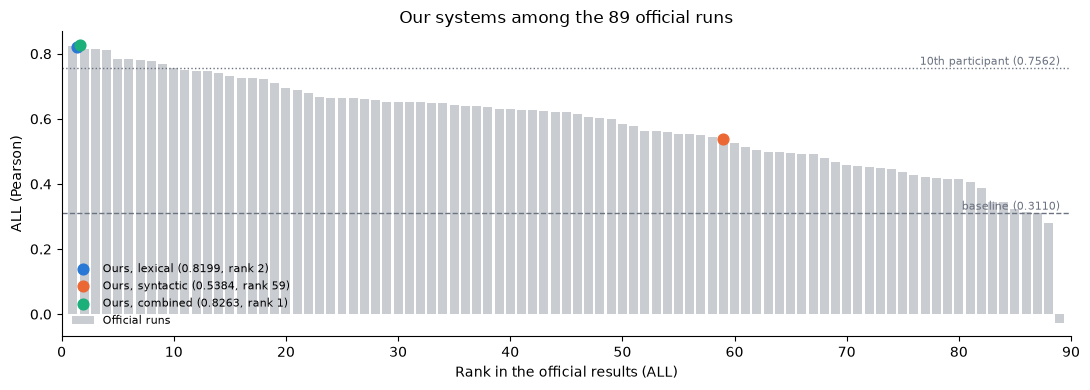

In [30]:
# Official ALL of every run, with our three systems (best lexical, syntactic and combined).
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(1, len(official) + 1), official["ALL"], color="#c9ccd1", width=0.8, label="Official runs")
ax.axhline(official.loc[10, "ALL"], color="#6b7280", linestyle=":", linewidth=1)
ax.text(len(official), official.loc[10, "ALL"] + 0.01, "10th participant (0.7562)", ha="right", fontsize=8, color="#6b7280")
ax.axhline(baseline["ALL"].iloc[0], color="#6b7280", linestyle="--", linewidth=1)
ax.text(len(official), baseline["ALL"].iloc[0] + 0.01, "baseline (0.3110)", ha="right", fontsize=8, color="#6b7280")
colors = {"lexical": "#2a78d6", "syntactic": "#eb6834", "combined": "#1baf7a"}
for group, model_name, strategy in chosen:
    value = summary.loc[(group, model_name, strategy), "ALL"]
    rank = official_rank(value)
    offset = {"lexical": -0.6, "syntactic": 0, "combined": 0.6}[group]  # lexical and combined have the same rank
    ax.scatter(rank + offset, value, color=colors[group], s=60, zorder=3, label=f"Ours, {group} ({value:.4f}, rank {rank})")
ax.set_xlabel("Rank in the official results (ALL)")
ax.set_ylabel("ALL (Pearson)")
ax.set_title("Our systems among the 89 official runs")
ax.set_xlim(0, len(official) + 1)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

### 7.3 Single model or one model per dataset?

In [35]:
# Effect of the training strategy for the selected features and model (test set).
strategy_effect = test_results[(test_results["features"] == SYSTEM[0]) & (test_results["model"] == SYSTEM[1])]
strategy_effect.set_index("strategy")[["ALL", "ALLnrm", "Mean"] + TEST_SETS].round(4)

,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews
strategy,,,,,,,,
single,0.7842,0.8610,0.6917,0.6949,0.8681,0.5448,0.6967,0.5134
per dataset,0.8263,0.8654,0.6946,0.6929,0.8784,0.5101,0.6967,0.5610


In [36]:
# ALL is a Pearson over the five test sets together, so it also depends on the scores being on the
# same scale across datasets. Mean predicted score of each test set, compared with the gold mean.
calibration = pd.DataFrame({
    "gold mean": {s: y[("test", s)].mean() for s in TEST_SETS},
    "single": {s: test_predictions[(SYSTEM[0], SYSTEM[1], "single")][s].mean() for s in TEST_SETS},
    "per dataset": {s: test_predictions[(SYSTEM[0], SYSTEM[1], "per dataset")][s].mean() for s in TEST_SETS},
})
calibration.round(3)

,gold mean,single,per dataset
MSRpar,3.271,3.440,3.284
MSRvid,2.297,2.301,2.262
SMTeuroparl,4.550,3.810,4.200
surprise.OnWN,3.871,3.153,3.153
surprise.SMTnews,4.335,3.646,4.099


**One model per dataset improves ALL by 0.0421 (0.7842 → 0.8263), but ALLnrm only by 0.0044 and Mean by 0.0029.** The per-dataset strategy does not rank the pairs inside each test set better (on SMTeuroparl it is even worse, 0.5448 → 0.5101); its main effect is on the **scale** of the predictions. ALL concatenates the five test sets, so it also rewards predicting the right average level for each dataset. The single model learns an average of the three training sets and under-predicts the machine translation sets, where almost all the pairs are near 5: the mean prediction for SMTeuroparl is 3.810 (gold 4.550) and for SMTnews 3.646 (gold 4.335). The SMTeuroparl model, trained only on high scores, predicts 4.200 and 4.099. This is why the ranking on ALL is more sensitive to the training strategy than ALLnrm and Mean, and why the best systems of the task also trained separate models. OnWN uses the single model in both strategies, so its predictions do not change (mean 3.153 for a gold mean of 3.871).

In [37]:
# Was the choice of the model for the surprise sets right? Each surprise set predicted with each possible model
# (selected features and model). This is an analysis after the fact: the choice was made before seeing these numbers.
make_model = MODELS[SYSTEM[1]]
columns = FEATURE_GROUPS[SYSTEM[0]]
candidates = {"single (all training data)": TRAIN_SETS, **{f"{s} model": [s] for s in TRAIN_SETS}}
routing = {}
for name, sets in candidates.items():
    model = make_model().fit(pd.concat([X[("train", s)][columns] for s in sets]), np.concatenate([y[("train", s)] for s in sets]))
    for surprise in ["surprise.OnWN", "surprise.SMTnews"]:
        prediction = np.clip(model.predict(X[("test", surprise)][columns]), 0, 5)
        routing.setdefault(name, {})[f"{surprise}: Pearson"] = pearsonr(y[("test", surprise)], prediction)[0]
        routing[name][f"{surprise}: mean prediction"] = prediction.mean()
routing = pd.DataFrame(routing).T
print({s: f"gold mean {y[('test', s)].mean():.3f}" for s in ["surprise.OnWN", "surprise.SMTnews"]})
routing.round(4)

{'surprise.OnWN': 'gold mean 3.871', 'surprise.SMTnews': 'gold mean 4.335'}


,surprise.OnWN: Pearson,surprise.OnWN: mean prediction,surprise.SMTnews: Pearson,surprise.SMTnews: mean prediction
single (all training data),0.6967,3.1527,0.5134,3.6464
MSRpar model,0.6563,3.3110,0.4467,3.4963
MSRvid model,0.6842,3.1347,0.4294,3.4203
SMTeuroparl model,0.6898,3.5480,0.5610,4.0988


**The model chosen beforehand for each surprise set was the best of the four options.** For OnWN, the single model gives the highest Pearson (0.6967), with the SMTeuroparl model very close (0.6898). For SMTnews, the SMTeuroparl model (0.5610) is clearly better than the single model (0.5134) and than the MSRpar and MSRvid models (0.4467 and 0.4294), as expected from section 5.4: a model trained on a similar source is better. This is also the main difference with UKP on SMTnews (0.4937): according to their paper, they predicted both surprise sets with a model trained on all the training data.

OnWN remains under-predicted with every model (mean prediction between 3.135 and 3.548, for a gold mean of 3.871): no training set has its kind of pairs, definitions of the same concept written with different words.

### 7.4 Which features matter?

In [38]:
# Ablation: remove one group of features from the combined set and train the selected model and strategy again.
ABLATION_GROUPS = {
    "word overlap": ["lex:jaccard_words", "lex:jaccard_lower", "lex:jaccard_lemmas", "lex:jaccard_content",
                     "lex:dice_content", "lex:containment_content"],
    "n-grams (lemma and char)": [c for c in ALL_FEATURES if "grams" in c and c.startswith("lex:")],
    "tf-idf and LCS": ["lex:tfidf_cosine", "lex:lcs_lemmas"],
    "WordNet": [c for c in ALL_FEATURES if "wordnet" in c or "mfs" in c],
    "numbers": [c for c in ALL_FEATURES if "numbers" in c],
    "length": ["lex:length_ratio", "lex:length_difference"],
    "syntactic: POS and chunks": [c for c in FEATURE_GROUPS["syntactic"] if c not in DEPENDENCY_FEATURES],
    "syntactic: dependencies": [c for c in FEATURE_GROUPS["syntactic"] if c in DEPENDENCY_FEATURES],
    "lexico-syntactic: categories and chunks": [c for c in ALL_FEATURES if c.startswith("lexsyn:") and c not in DEPENDENCY_FEATURES],
    "lexico-syntactic: dependencies": [c for c in ALL_FEATURES if c.startswith("lexsyn:") and c in DEPENDENCY_FEATURES],
}
assert sorted(sum(ABLATION_GROUPS.values(), [])) == sorted(ALL_FEATURES)
# Larger groups, which overlap with the ones above.
ABLATION_GROUPS |= {
    "all syntactic": FEATURE_GROUPS["syntactic"],
    "all lexico-syntactic": [c for c in ALL_FEATURES if c.startswith("lexsyn:")],
    "all from the dependency trees (spaCy)": DEPENDENCY_FEATURES,
}

reference = evaluate(train_and_predict(FEATURE_GROUPS["combined"], MODELS[SYSTEM[1]], SYSTEM[2]))
ablation = []
for name, removed in ABLATION_GROUPS.items():
    columns = [c for c in FEATURE_GROUPS["combined"] if c not in removed]
    result = evaluate(train_and_predict(columns, MODELS[SYSTEM[1]], SYSTEM[2]))
    cv = scores(train_gold, cross_validate(columns, MODELS[SYSTEM[1]], SYSTEM[2]), TRAIN_SETS)
    ablation.append({"removed group": name, "features": len(removed), "Δ CV ALL": cv["ALL"] - best_cv.loc["combined", "ALL"],
                     **{f"Δ {m}": result[m] - reference[m] for m in ["ALL", "Mean"] + TEST_SETS}})
print(f"Combined features, {SYSTEM[1]}, {SYSTEM[2]}: ALL = {reference['ALL']:.4f}, Mean = {reference['Mean']:.4f}")
ablation = pd.DataFrame(ablation).set_index("removed group")
ablation.round(4)

Combined features, RF, per dataset: ALL = 0.8263, Mean = 0.6946


,features,Δ CV ALL,Δ ALL,Δ Mean,Δ MSRpar,Δ MSRvid,Δ SMTeuroparl,Δ surprise.OnWN,Δ surprise.SMTnews
removed group,,,,,,,,,
word overlap,6,-0.0005,0.0001,-0.0012,0.0008,-0.0001,-0.0053,-0.0004,-0.0036
n-grams (lemma and char),6,-0.0010,-0.0050,-0.0157,-0.0104,-0.0012,-0.0304,-0.0173,-0.0329
tf-idf and LCS,2,-0.0027,-0.0011,0.0018,-0.0002,-0.0039,0.0054,0.0043,0.0074
WordNet,4,-0.0033,-0.0027,-0.0085,0.0081,-0.0069,-0.0400,-0.0096,-0.0045
numbers,4,-0.0022,-0.0038,-0.0068,-0.0269,0.0002,0.0003,-0.0035,0.0030
length,2,-0.0014,-0.0060,-0.0200,-0.0053,-0.0007,-0.0482,-0.0052,-0.0798
syntactic: POS and chunks,16,-0.0024,-0.0029,-0.0040,-0.0051,0.0020,-0.0091,-0.0020,-0.0112
syntactic: dependencies,5,-0.0000,0.0028,0.0057,-0.0015,0.0001,0.0254,-0.0008,0.0193
lexico-syntactic: categories and chunks,9,-0.0013,0.0000,-0.0019,0.0008,-0.0023,-0.0017,-0.0040,-0.0028


                             MSRpar  MSRvid  SMTeuroparl
lex:wordnet_path              0.029   0.241       -0.017
lex:tfidf_cosine              0.005   0.197        0.004
lex:wordnet_lin               0.097   0.013        0.029
lex:numbers_included          0.053   0.000        0.000
lex:length_ratio              0.006   0.000        0.025
syn:cosine_dep_labels         0.002   0.000        0.016
lex:numbers_close             0.014  -0.000       -0.002
lexsyn:jaccard_nouns          0.002   0.014       -0.001
lexsyn:jaccard_NP_heads       0.001   0.001        0.014
syn:proportion_difference_V  -0.001  -0.000        0.013
lex:jaccard_lemmas            0.004  -0.000        0.013
lexsyn:role_root              0.000   0.012        0.002


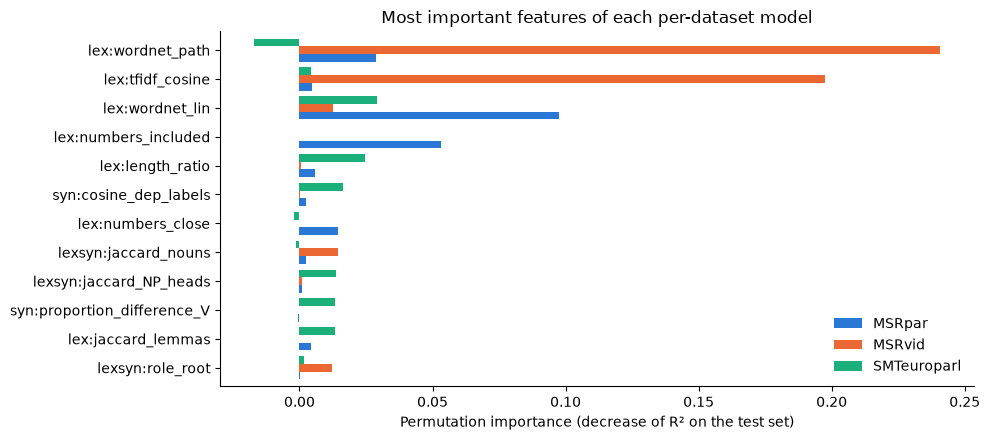

In [39]:
# Permutation importance of each feature for the model of each training set (combined features),
# measured on the corresponding test set (decrease of R² when the feature is shuffled).
importances = {}
for s in TRAIN_SETS:
    model = MODELS[SYSTEM[1]]().fit(X[("train", s)][FEATURE_GROUPS["combined"]], y[("train", s)])
    result = permutation_importance(model, X[("test", s)][FEATURE_GROUPS["combined"]], y[("test", s)],
                                    n_repeats=5, random_state=0, n_jobs=-1)
    importances[s] = pd.Series(result.importances_mean, index=FEATURE_GROUPS["combined"])
importances = pd.DataFrame(importances)
top = importances.loc[importances.max(axis=1).sort_values(ascending=False).index[:12]]
print(top.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
top[::-1].plot.barh(ax=ax, color=["#2a78d6", "#eb6834", "#1baf7a"], width=0.8)
ax.set_xlabel("Permutation importance (decrease of R² on the test set)")
ax.set_title("Most important features of each per-dataset model")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [40]:
# The syntactic dimension alone, with and without the dependency features (selected model and strategy).
rows = {}
for name, columns in [("POS and chunks (NLTK)", [c for c in FEATURE_GROUPS["syntactic"] if c not in DEPENDENCY_FEATURES]),
                      ("dependencies (spaCy)", [c for c in FEATURE_GROUPS["syntactic"] if c in DEPENDENCY_FEATURES]),
                      ("POS, chunks and dependencies", FEATURE_GROUPS["syntactic"])]:
    cv = scores(train_gold, cross_validate(columns, MODELS[SYSTEM[1]], SYSTEM[2]), TRAIN_SETS)
    test = evaluate(train_and_predict(columns, MODELS[SYSTEM[1]], SYSTEM[2]))
    rows[name] = {"features": len(columns), "CV ALL": cv["ALL"], "CV Mean": cv["Mean"], "test ALL": test["ALL"],
                  "test Mean": test["Mean"], "rank (ALL)": official_rank(test["ALL"])}
pd.DataFrame(rows).T.round(4)

,features,CV ALL,CV Mean,test ALL,test Mean,rank (ALL)
POS and chunks (NLTK),16.0,0.6777,0.4312,0.5337,0.2812,60.0
dependencies (spaCy),5.0,0.6592,0.4101,0.4756,0.2391,69.0
"POS, chunks and dependencies",21.0,0.6972,0.4856,0.5384,0.3163,59.0


The table gives, for each group of features, the change when the group is removed, in cross-validation (Δ CV ALL) and on the test set. As a reference for the size of the noise: the standard deviation of ALL is 0.0010 over the fold assignments (section 5.3) and 0.0008 over the seeds of the forest (section 6). **Most of the changes are of this order, so the groups are largely redundant**: the forest replaces a removed group with the correlated measures that remain.

**Lexical features carry almost all the information.** The best individual features are lexical: the WordNet aligned similarity with the Path measure (mean Pearson 0.669 over the training sets), the TF-IDF cosine (0.632) and the WordNet Lin similarity (0.630). They are also the most important ones in the permutation importance: `wordnet_path` and `tfidf_cosine` for MSRvid (0.241 and 0.197), `wordnet_lin` for MSRpar (0.097).

**Some groups matter for one kind of data:**

- **Length** for the translation sets (SMTnews -0.0798, SMTeuroparl -0.0482): a bad translation is often shorter or longer than the source. It is the group with the largest effect on Mean (-0.0200).
- **WordNet** for SMTeuroparl (-0.0400): it matches synonyms and related words that word overlap misses.
- **Character and lemma n-grams** for the translation sets (-0.0304 and -0.0329) and OnWN (-0.0173).
- **Numbers** for MSRpar (-0.0269), the news set with many figures: `numbers_included` is the 2nd most important feature of the MSRpar model (0.053) and the new `numbers_close` the 4th (0.014).

**The syntactic dimension alone is weak** (test ALL 0.5384, rank 59, although still well above the baseline 0.3110). Two sentences with the same structure can mean completely different things. This is clear in MSRvid, where most sentences have the same pattern (*"A man is V-ing a N"*): the overlap of POS unigrams is even *negatively* correlated with the gold score there (-0.154), because the pairs with different structures are often the paraphrases. The dependency features improve it in cross-validation (ALL 0.6777 with the 16 POS and chunk features, 0.6972 with the 21 features; Mean 0.4312 → 0.4856), but much less on the test set (ALL 0.5337 → 0.5384, Mean 0.2812 → 0.3163): the dimension remains far from the lexical one.

**Syntax helps when it is tied to the words, not as an independent signal.** Removing all the 21 purely syntactic features does not hurt on the test set (ALL +0.0029, Mean +0.0108, with SMTnews +0.0506 and SMTeuroparl +0.0331), although it costs a little in cross-validation (-0.0021). Removing the 14 lexico-syntactic features costs in both (-0.0029 in cross-validation, -0.0066 on the test set). The purely syntactic features are useful on the training sources and misleading on the translation test sets; the lexico-syntactic ones (words compared within the same category, chunk or dependency relation) are consistently useful.

**The dependency features of spaCy.** Without the 10 features computed from the dependency trees, the system uses NLTK only: its ALL is 0.0038 lower and its Mean 0.0014 higher (in cross-validation, ALL -0.0009). So the NLTK-only system is also at the level of the best official system, and the conclusions of this notebook do not depend on the parser. Inside the group, the two halves behave as above: the lexicalized dependency features help (-0.0065 when removed), and the unlexicalized ones hurt on the test set (+0.0028).